In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn 

### EDA

In [5]:
import pandas as pd

# Load the sales data with error handling
try:
    sales_data = pd.read_csv('Data/sales_data.csv', on_bad_lines='skip')
    print(sales_data.head())
except pd.errors.ParserError as e:
    print(f"Error parsing file: {e}")


       date product_type  sales
0  1/1/2023            A   50.0
1  1/1/2023            B   30.0
2  1/2/2023            A   60.0
3  1/2/2023            B   40.0
4  1/3/2023            A   75.0


   product_id product_name  quantity_in_stock  reorder_level
0           1    Product_A                100             30
1           2    Product_B                 80             25
2           3    Product_C                120             40
3           4    Product_D                 60             20
4           5    Product_E                 90             35


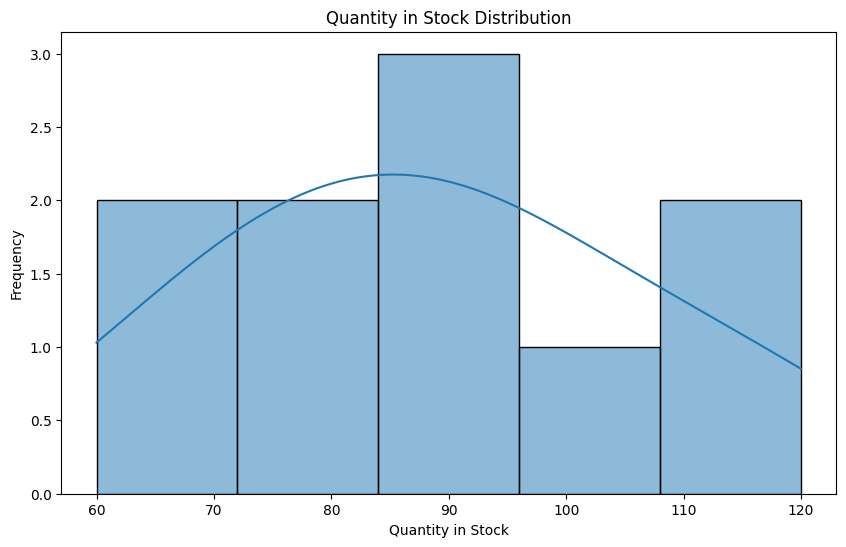

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the inventory data
inventory_data = pd.read_csv('Data/inventory_data.csv')
print(inventory_data.head())


# Visualize the quantity in stock
plt.figure(figsize=(10, 6))
sns.histplot(inventory_data['quantity_in_stock'], kde=True)
plt.title('Quantity in Stock Distribution')
plt.xlabel('Quantity in Stock')
plt.ylabel('Frequency')
plt.show()

# Place this in your EDA notebook or inventory optimization script
import numpy as np
from scipy.optimize import minimize

holding_cost = 1.0
stockout_cost = 10.0

# Objective function
def objective_function(x, actual_inventory, reorder_level):
    holding = holding_cost * np.maximum(0, x - reorder_level)
    stockout = stockout_cost * np.maximum(0, reorder_level - x)
    return holding.sum() + stockout.sum()

# Generate the 'optimal_inventory' column
optimal_inventory_levels = []
for product in inventory_data['product_id'].unique():
    product_data = inventory_data[inventory_data['product_id'] == product]
    actual_inventory = product_data['quantity_in_stock'].values
    reorder_level = product_data['reorder_level'].values
    initial_guess = np.mean(actual_inventory)
    constraints = {'type': 'ineq', 'fun': lambda x: x}

    result = minimize(objective_function, initial_guess, args=(actual_inventory, reorder_level), constraints=constraints)
    optimal_inventory_levels.append(result.x)

inventory_data['optimal_inventory'] = np.concatenate(optimal_inventory_levels)
print(inventory_data.head())  # Verify the column is added



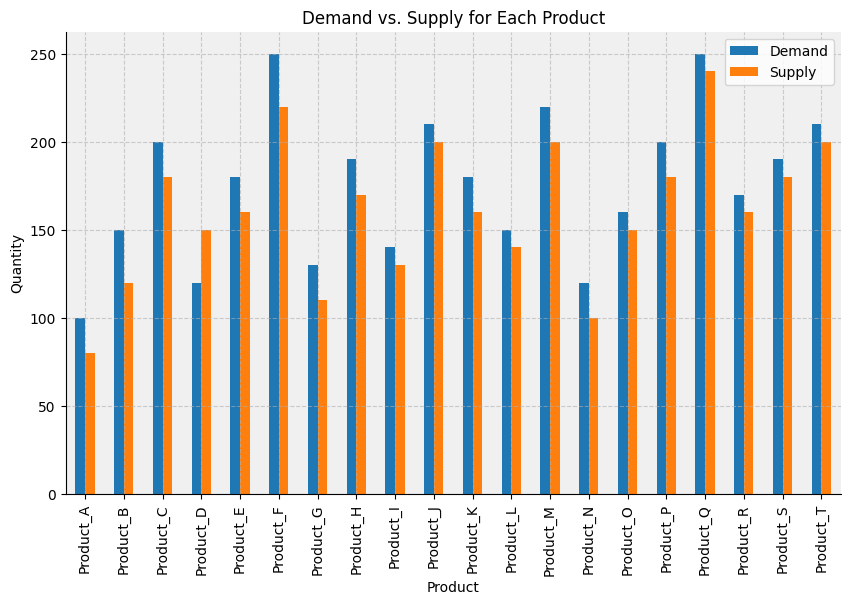

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the demand_supply_data dataset
demand_supply_data = pd.read_csv('Data/demand_supply_data.csv')

# Create a bar chart for demand and supply
demand_supply_data.plot(kind='bar', x='Product', y=['Demand', 'Supply'], figsize=(10, 6))
plt.title('Demand vs. Supply for Each Product')
plt.xlabel('Product')
plt.ylabel('Quantity')
plt.grid(True, linestyle='--', alpha=0.6)
plt.gca().set_facecolor('#f0f0f0')
plt.gca().spines['top'].set_color('none')
plt.gca().spines['right'].set_color('none')
plt.show()


In [9]:
# Calculate the difference between demand and supply
demand_supply_data['Difference'] = demand_supply_data['Supply'] - demand_supply_data['Demand']

# Identify products with surpluses and shortages
surpluses = demand_supply_data[demand_supply_data['Difference'] > 0]
shortages = demand_supply_data[demand_supply_data['Difference'] < 0]

print("Products with Surpluses:")
print(surpluses[['Product', 'Difference']])

print("\nProducts with Shortages:")
print(shortages[['Product', 'Difference']])


Products with Surpluses:
     Product  Difference
3  Product_D          30

Products with Shortages:
      Product  Difference
0   Product_A         -20
1   Product_B         -30
2   Product_C         -20
4   Product_E         -20
5   Product_F         -30
6   Product_G         -20
7   Product_H         -20
8   Product_I         -10
9   Product_J         -10
10  Product_K         -20
11  Product_L         -10
12  Product_M         -20
13  Product_N         -20
14  Product_O         -10
15  Product_P         -20
16  Product_Q         -10
17  Product_R         -10
18  Product_S         -10
19  Product_T         -10
